In [2]:
#stage one
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
raw = pd.read_csv('../data/raw/raw_energy_prices.csv',
                  header = [0,1], skiprows = [2],
                  index_col = 0,
                  parse_dates=True
                  )

print(type(raw.index[0]))

#raw.info()
raw.head()
#raw.dtypes
print('\n')
prices = raw["Close"]

log_return = np.log(prices).diff().dropna()
prices.head()
print(log_return.shape)       # should be (1254, 2)
print('\n')
print(log_return.mean().round(4))      # ICLN ≈ -0.0004, IXC ≈ 0.0007
print('\n')
print(log_return.std().round(4))       # ICLN ≈ 0.018,  IXC ≈ 0.015

<class 'pandas.Timestamp'>


(1254, 2)


Ticker
ICLN   -0.0004
IXC     0.0007
dtype: float64


Ticker
ICLN    0.0181
IXC     0.0151
dtype: float64


### Stage 1: Questions & Answers

#### **1. What does a daily std of 0.018 mean?**
* **Meaning:** A daily standard deviation of $0.018$ for log returns means that on any given trading day, the price of ICLN typically fluctuates by approximately **1.8%** (since log returns approximate percentage changes for small values).
* **Comparison:**
  * **ICLN (Clean Energy):** Has a typical daily move of roughly **1.81%** ($	\text{std} \approx 0.0181$).
  * **IXC (Global Energy):** Has a typical daily move of roughly **1.51%** ($	\text{std} \approx 0.0151$).
  * **Conclusion:** This indicates that ICLN experienced higher price volatility than IXC over the analyzed period.

---

#### **2. Close vs. Adj Close: Why is it OK that there's no "Adj Close" column?**
* **Reason:** When downloading historical data using libraries like `yfinance` with `auto_adjust=True` (which is often the default setting), the library automatically replaces the regular "Close" price with the dividend-and-split-adjusted price.
* Because the adjustments are applied directly to the "Close" column, a separate "Adj Close" column is redundant and not included.

---Summary Table---

          Mean     Std  Skewness  Excess Kurtosis     Min     Max
Ticker                                                           
ICLN   -0.0004  0.0181    0.1972           2.0411 -0.0762  0.0802
IXC     0.0007  0.0151   -0.4687           2.6731 -0.0884  0.0682

extreme days (min)
Ticker
ICLN   2024-11-06
IXC    2025-04-04
dtype: datetime64[us]

extreme days (max)
Ticker
ICLN   2021-03-09
IXC    2025-04-09
dtype: datetime64[us]

Comparison Table
                 Within ±1σ (share)  Beyond ±3σ (days)
Normal predicts              0.6827             3.3855
ICLN                         0.7520            19.0000
IXC                          0.7408            12.0000

within 1 sigma
Ticker
ICLN    0.7520
IXC     0.7408
dtype: float64

within 2 sigma
Ticker
ICLN    0.9498
IXC     0.9530
dtype: float64

within 3 sigma
Ticker
ICLN    0.9848
IXC     0.9904
dtype: float64




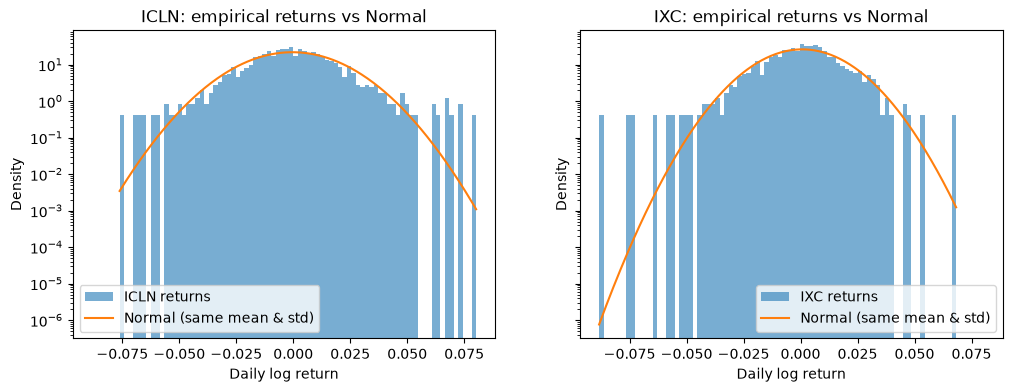

In [3]:
#stage 2
summary_table = pd.DataFrame({
    'Mean': log_return.mean(),
    'Std': log_return.std(),
    'Skewness': log_return.skew(),
    'Excess Kurtosis': log_return.kurtosis(),
    'Min': log_return.min(),
    'Max': log_return.max(),
})
print('---Summary Table---\n')
print(summary_table.round(4))

extreme_days_min = log_return.idxmin()
extreme_days_max = log_return.idxmax()
print('\nextreme days (min)')
print(extreme_days_min)
print('\nextreme days (max)')
print(extreme_days_max)

pct_68_rule_test_distance = (log_return - log_return.mean()).abs()
within_1_sd = pct_68_rule_test_distance <= log_return.std()
within_2_sd = pct_68_rule_test_distance <= 2 * log_return.std()
within_3_sd = pct_68_rule_test_distance <= 3 * log_return.std()
beyond_3_sd = pct_68_rule_test_distance > 3 * log_return.std()
n = len(log_return)                                   # 1254 days
normal_1sd = stats.norm.cdf(1) - stats.norm.cdf(-1)   # P(−1 < Z < 1) ≈ 0.683
normal_3sd = 2 * stats.norm.sf(3)                     # P(|Z| > 3)   ≈ 0.0027

comparison = pd.DataFrame({
    'Within ±1σ (share)': [normal_1sd, within_1_sd.mean()['ICLN'], within_1_sd.mean()['IXC']],
    'Beyond ±3σ (days)':  [normal_3sd*n, beyond_3_sd.sum()['ICLN'], beyond_3_sd.sum()['IXC']],
    }, index=['Normal predicts', 'ICLN', 'IXC'])

print('\nComparison Table')
print(comparison.round(4))
print('\nwithin 1 sigma')
print(within_1_sd.mean().round(4))   # True=1, False=0 → proportion of days
print('\nwithin 2 sigma')
print(within_2_sd.mean().round(4))   # True=1, False=0 → proportion of days
print('\nwithin 3 sigma')
print(within_3_sd.mean().round(4))

print('\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, ticker in zip(axes, ["ICLN", "IXC"]):
    x = log_return[ticker]          # picks ICLN, then IXC
    mu = x.mean()
    sigma = x.std()
    grid = np.linspace(x.min(), x.max(), 300)
    normal_y = stats.norm.pdf(grid, mu, sigma)
    ax.hist(x, bins=80, density=True, alpha=0.6, label=f"{ticker} returns")
    ax.plot(grid, normal_y, label="Normal (same mean & std)")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.set_title(f"{ticker}: empirical returns vs Normal")
    ax.set_yscale("log")
    ax.legend()

plt.savefig("../outputs/figures/fig_hist_vs_normal.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 2: Questions & Answers

#### **1. Which ETF has fatter tails, and which leans toward crashes? Does that match your guess about oil vs clean-energy news?**
* **Fatter Tails:** **IXC** (Global Energy) has slightly fatter tails overall, as shown by its higher **Excess Kurtosis of 2.67** compared to ICLN's **2.04**. High excess kurtosis indicates a higher probability of extreme events occurring in both directions.
* **Leans Toward Crashes:** **IXC** has a negative skewness (**-0.469**), meaning its distribution is left-skewed with a longer tail of extreme negative returns (crashes). This is highlighted by its worst single-day drop of **-8.84%** (compared to ICLN's worst drop of **-7.62%**). Conversely, **ICLN** has a positive skewness (**0.197**), meaning it leans slightly more towards occasional positive spikes.
* **Real-World Alignment:** This matches historical trends. Traditional fossil-fuel energy (IXC) is highly sensitive to sudden global geopolitical crises, supply shocks, and macroeconomic demand collapses (e.g., oil price crashes), leading to abrupt left-tail events (crashes). Clean energy (ICLN) is heavily driven by policy announcements, subsidies, and retail investor optimism, which can often generate sudden positive price spikes (right-tail events).

---

#### **2. 19 and 12 days beyond 3σ vs 3.386 predicted: how many times more?**
* **ICLN:** 19 actual days / 3.386 predicted days $\approx$ **5.61 times more** extreme outlier days than a normal distribution expects.
* **IXC:** 12 actual days / 3.386 predicted days $\approx$ **3.54 times more** extreme outlier days than expected.
* Both results underscore that financial returns are far from normally distributed and exhibit strong "fat-tailed" behaviors.

---

#### **3. Why is "more days within ±1σ" consistent with fat tails?**
* **The Conservation of Probability:** For any probability distribution, the total area under the curve must sum to 1.
* **How Fat Tails Form:** Since fat-tailed distributions have a significantly higher probability of extreme outliers (beyond $\pm3\sigma$), and their variance ($\%\text{std}$) is calculated based on these large outlier deviations, the bulk of the everyday "normal" returns must bunch up much closer to the mean to offset those distant outliers.
* Therefore, to accommodate both a high standard deviation (driven by extreme days) and a total area of 1, a fat-tailed distribution has a higher, narrower peak near the center, resulting in **more daily returns falling within $\pm1\sigma$** ($\approx 74\% - 75\%$) than the standard Normal distribution predicts ($68.3\%$).

-0.0004 0.0181


(np.float64(-0.00038918561937578087), np.float64(0.01809870520422434))


5.0361 -0.0006 0.0142


0.0183


      Normal loc  Normal scale    t nu   t loc  t scale  t implied std
ICLN     -0.0004        0.0181  5.0361 -0.0006   0.0142         0.0183
IXC       0.0007        0.0151  5.4689  0.0011   0.0121         0.0183


0.0152


[-1.1209  1.2797  2.8625  3.2323  3.2425]


3477.6641
3520.8328


3520.8328


-6951.3282 -7035.6655 84.33730000000014


      Normal loc  Normal scale    t nu   t loc  t scale  t implied std  \
ICLN     -0.0004        0.0181  5.0361 -0.0006   0.0142         0.0183   
IXC       0.0007        0.0151  5.4689  0.0011   0.0121         0.0152   

      LL Normal       LL t  AIC Normal      AIC t  ΔAIC (Normal − t)  
ICLN  3251.5923  3295.9365  -6499.1847 -6585.8729            86.6883  
IXC   3477.6641  3520.8328  -6951.3282 -7035.6655            84.3373  


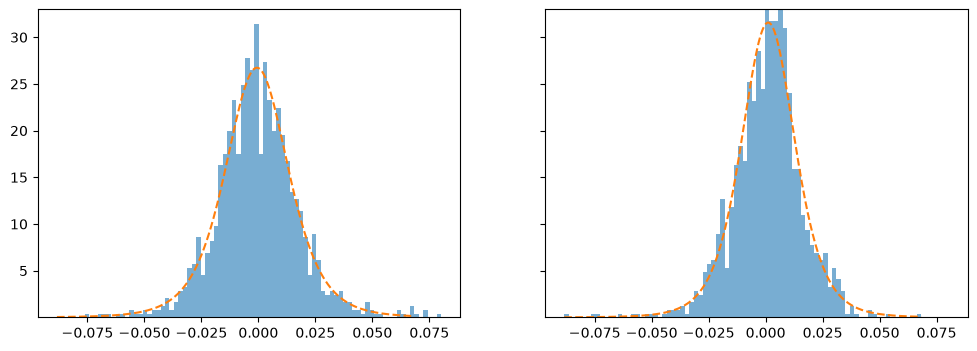



   k  Empirical  Normal  Student's t
0  1     0.2480  0.3171       0.2581
1  2     0.0502  0.0454       0.0510
2  3     0.0152  0.0027       0.0122
3  4     0.0032  0.0001       0.0037
4  5     0.0000  0.0000       0.0014


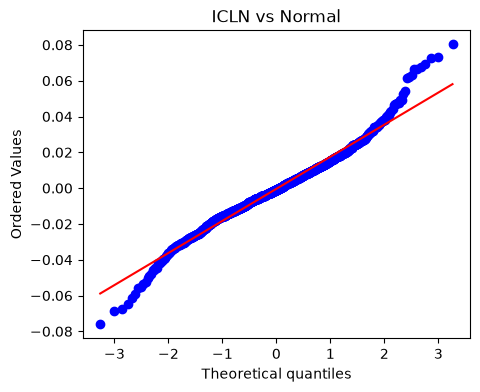

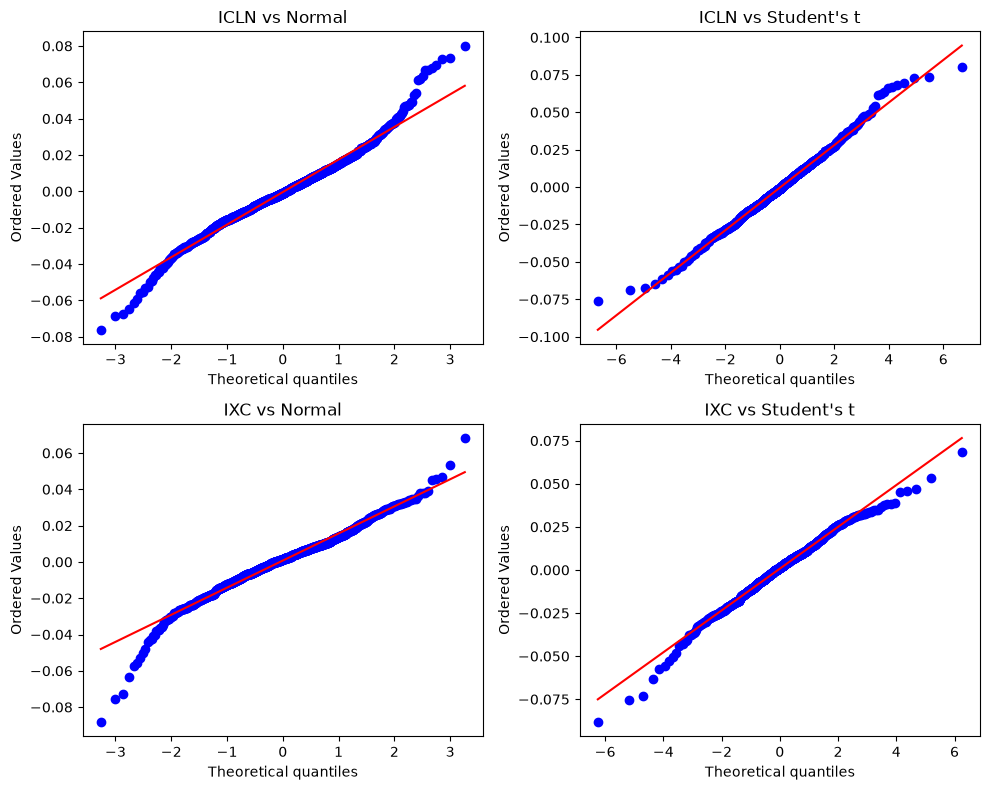

In [4]:
#stage 3
x = log_return["ICLN"]
n_loc, n_scale = stats.norm.fit(x)
print(n_loc.round(4), n_scale.round(4))     # (-0.000389..., 0.01809...)
print('\n')
print(stats.norm.fit(x))     # (-0.000389..., 0.01809...)

nu, t_loc, t_scale = stats.t.fit(x)
print('\n')
print(nu.round(4), t_loc.round(4), t_scale.round(4))     # (3.187..., -0.000389..., 0.01809...)

implied_std = t_scale * np.sqrt(nu / (nu - 2))
print('\n')
print(implied_std.round(4))          # should be close to 0.0181

fit_results = {}                          # 1. empty dict before the loop

for ticker in ["ICLN", "IXC"]:
    x = log_return[ticker]
    n_loc, n_scale = stats.norm.fit(x)
    nu, t_loc, t_scale = stats.t.fit(x)

    fit_results[ticker] = {               # 2. one entry per ticker
        "Normal loc": n_loc,
        "Normal scale": n_scale,
        "t nu": nu,
        "t loc": t_loc,
        "t scale": t_scale,
        "t implied std": implied_std,
    }

fit_table = pd.DataFrame(fit_results).T   # 3. after the loop
fit_results = {}                          # 1. empty dict before the loop

for ticker in ["ICLN", "IXC"]:
    x = log_return[ticker]
    n_loc, n_scale = stats.norm.fit(x)
    nu, t_loc, t_scale = stats.t.fit(x)

    fit_results[ticker] = {               # 2. one entry per ticker
        "Normal loc": n_loc,
        "Normal scale": n_scale,
        "t nu": nu,
        "t loc": t_loc,
        "t scale": t_scale,
        "t implied std": implied_std,          # your Step 3 formula
    }

fit_table = pd.DataFrame(fit_results).T   # 3. after the loop
print('\n')
print(fit_table.round(4))

print('\n')
print((t_scale * np.sqrt(nu / (nu - 2))).round(4))

print('\n')
daily_ll = stats.norm.logpdf(x, n_loc, n_scale)
print(daily_ll[:5].round(4))   # first 5 days, should be [-4.0861, -4.0861, -4.0861, -4.0861, -4.0861]
ll_normal = daily_ll.sum().round(4) 
print('\n')
print(ll_normal)   # should be -1,905.7 

nu, t_loc, t_scale = stats.t.fit(x)
ll_t = stats.t.logpdf(x, nu, t_loc, t_scale).sum()
print(ll_t.round(4))                                       # ≈ 3295.9
print('\n')
print(stats.t.logpdf(x, nu, t_loc, t_scale).sum().round(4))   # should be -1,898.3
n_aic = 2 * 2 - 2 * ll_normal   # 2 params for Normal
t_aic = 2 * 3 - 2 * ll_t   # 3 params for Student's t
print('\n')
print(n_aic.round(4), t_aic.round(4), n_aic - t_aic.round(4))   # should be 3,817.4, 3,802.6, 14.8
print('\n')

fit_results = {}                          # 1. empty dict before the loop
for ticker in ["ICLN", "IXC"]:
    x = log_return[ticker]
    n_loc, n_scale = stats.norm.fit(x)
    nu, t_loc, t_scale = stats.t.fit(x)
    implied_std = t_scale * np.sqrt(nu / (nu - 2))
    daily_ll = stats.norm.logpdf(x, n_loc, n_scale)
    ll_normal = daily_ll.sum()
    ll_t = stats.t.logpdf(x, nu, t_loc, t_scale).sum()
    n_aic = 2 * 2 - 2 * ll_normal   # 2 params for Normal
    t_aic = 2 * 3 - 2 * ll_t   # 3 params for Student's t
    fit_results[ticker] = {
        "Normal loc": n_loc,
        "Normal scale": n_scale,
        "t nu": nu,
        "t loc": t_loc,
        "t scale": t_scale,
        "t implied std": implied_std,
        "LL Normal": ll_normal,
        "LL t": ll_t,
        "AIC Normal": n_aic,
        "AIC t": t_aic,
        "ΔAIC (Normal − t)": n_aic - t_aic,
    }
fit_table = pd.DataFrame(fit_results).T            # level 0: after the loop
print(fit_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, ticker in zip(axes, ["ICLN", "IXC"]):
    x = log_return[ticker]
    mu      = fit_table.loc[ticker, "Normal loc"]
    sigma   = fit_table.loc[ticker, "Normal scale"]
    nu      = fit_table.loc[ticker, "t nu"]
    t_loc   = fit_table.loc[ticker, "t loc"]
    t_scale = fit_table.loc[ticker, "t scale"]
    normal_y = stats.norm.pdf(grid, mu, sigma)
    t_y = stats.t.pdf(grid, nu, t_loc, t_scale)
    ax.hist(x, bins=80, density=True, alpha=0.6, label=f"{ticker} returns")
    ax.plot(grid, t_y, linestyle="--", label=f"Student's t (ν={nu:.1f})")
    ax.set_ylim(bottom=1e-3)
    plt.savefig("../outputs/figures/fig_hist_normal_vs_t.png", dpi=150, bbox_inches="tight")
plt.show()

x = log_return["ICLN"]
mu = x.mean()
s = x.std()
k = 3
threshold = k * s

emp = ((x - mu).abs() > threshold).mean()   # empirical proportion of days beyond ±3σ


nu      = fit_table.loc["ICLN", "t nu"]
t_loc   = fit_table.loc["ICLN", "t loc"]
t_scale = fit_table.loc["ICLN", "t scale"]
n_loc = fit_table.loc["ICLN", "Normal loc"]   # log-likelihood for Normal
n_scale = fit_table.loc["ICLN", "Normal scale"]   # scale parameter for Normal


p_normal = stats.norm.sf(mu + threshold, n_loc, n_scale) + stats.norm.cdf(mu - threshold, n_loc, n_scale)   # theoretical proportion of days beyond ±3σ for Normal
p_t = (stats.t.sf(mu + threshold, nu, t_loc, t_scale) + stats.t.cdf(mu - threshold, nu, t_loc, t_scale))   # theoretical proportion of days beyond ±3σ for Student's t

rows = []
for k in [1,2,3,4,5]:
    threshold = k * s
    emp = ((x - mu).abs() > threshold).mean()
    p_normal = stats.norm.sf(mu + threshold, n_loc, n_scale) + stats.norm.cdf(mu - threshold, n_loc, n_scale)
    p_t = (stats.t.sf(mu + threshold, nu, t_loc, t_scale) + stats.t.cdf(mu - threshold, nu, t_loc, t_scale))
    rows.append({
        "k": k,
        "Empirical": emp,
        "Normal": p_normal,
        "Student's t": p_t,
    })
    
tail_table = pd.DataFrame(rows)
print('\n')
print(tail_table.round(4)) 

rows = []
for ticker in ["ICLN", "IXC"]:
    x = log_return[ticker]
    mu, s = x.mean(), x.std()
    e_abs = x.abs().mean()
    # get n_loc, n_scale, nu, t_loc, t_scale from fit_table for THIS ticker

    for k in [1, 2, 3, 4, 5]:                # inner loop: indented one more level
        threshold = k * s
        emp = ((x - mu).abs() > threshold).mean()
        # get n_loc, n_scale, nu, t_loc, t_scale from fit_table for THIS ticker
        n_loc = fit_table.loc[ticker, "Normal loc"]
        n_scale = fit_table.loc[ticker, "Normal scale"]
        nu = fit_table.loc[ticker, "t nu"]
        t_loc = fit_table.loc[ticker, "t loc"]
        t_scale = fit_table.loc[ticker, "t scale"]
        p_normal = stats.norm.sf(mu + threshold, n_loc, n_scale) + stats.norm.cdf(mu - threshold, n_loc, n_scale)
        p_t = (stats.t.sf(mu + threshold, nu, t_loc, t_scale) + stats.t.cdf(mu - threshold, nu, t_loc, t_scale))
        markov  = min(1, e_abs / threshold)  
        emp_abs = (x.abs() >= threshold).mean()
        rows.append({"Ticker": ticker, "k": k, "Empirical": emp, "Normal": p_normal, "Student's t": p_t, "Markov bound": markov, "Empirical |r|": emp_abs})       # ← NEW (stored in the row)

tail_table = pd.DataFrame(rows)

n = len(x)
tail_table["Empirical days"] = tail_table["Empirical"] * n
tail_table["Normal days"]    = tail_table["Normal"] * n
tail_table["t days"]         = tail_table["Student's t"] * n
tail_table["Actual ÷ Normal"] = tail_table["Empirical"] / tail_table["Normal"]
tail_table["Markov ÷ Empirical"] = tail_table["Markov bound"] / tail_table["Empirical |r|"]
tail_table["Markov holds?"]      = tail_table["Markov bound"] >= tail_table["Empirical |r|"]



tail_table.to_csv("../outputs/tables/tab_tail_probabilities.csv", index=False, float_format="%.4g")

fig, ax = plt.subplots(figsize=(5, 4))
x = log_return["ICLN"]
stats.probplot(x, dist="norm", plot=ax)
ax.set_title("ICLN vs Normal")
plt.show()

nu = fit_table.loc["ICLN", "t nu"]
stats.probplot(x, dist=stats.t, sparams=(nu,), plot=ax)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for row, ticker in enumerate(["ICLN", "IXC"]):
    x  = log_return[ticker]
    nu = fit_table.loc[ticker, "t nu"]

    stats.probplot(x, dist="norm", plot=axes[row, 0])
    axes[row, 0].set_title(f"{ticker} vs Normal")

    stats.probplot(x, dist=stats.t, sparams=(nu,), plot=axes[row, 1])
    axes[row, 1].set_title(f"{ticker} vs Student's t")

plt.tight_layout()
plt.savefig("../outputs/figures/fig_qq_normal_vs_t.png", dpi=150, bbox_inches="tight")
plt.show()

Stage 3: Normal vs Student’s t (Method 1)

Fit and AIC (Tasks 1–2)

The fitted t has ν ≈ 5.0 for ICLN and 5.5 for IXC. That’s typical of fat-tailed daily stock returns, and far from Normal (ν → ∞).
The t wins clearly for both: ΔAIC ≈ 87 (ICLN) and 84 (IXC), far above the “strong evidence” level of 10.
The t’s scale (0.0142 / 0.0121) is smaller than the sample std, but the implied std of 0.0183 / 0.0152 matches the data.
Why it matters: even after penalising the t for its extra parameter, it explains the data much better. But AIC only says the t is better than the Normal, not that it’s correct. The tail table and QQ plots check that.

Histogram with curves (Task 3)

The Normal curve sits below the histogram at the peak and in the far tails, and above it in the shoulders (around ±1–2σ). The t follows all three regions much more closely.
Why: fat-tailed data has more very quiet days and more extreme days, and fewer medium-sized ones. A Normal with the same std can’t produce that shape.

Tail table (Task 4)

Where the Normal fails: at k = 1 it overpredicts (Actual ÷ Normal ≈ 0.8 for both), at k = 2 it’s about right (≈ 1.0–1.1), and beyond that it badly underpredicts: 5.6× at 3σ and 51× at 4σ for ICLN; 3.6× and 63× for IXC.
Why: this is the fat-tail signature again. The Normal puts too much probability on medium moves and almost none on extreme ones.
How close the t is: within a few days at every k, with errors in both directions. ICLN at 3σ: 15.2 predicted vs 19 actual; at 4σ: 4.6 vs 4. IXC at 3σ: 14.0 vs 12; at 4σ: 4.0 vs 5; at 5σ: 1.4 vs 2. For IXC, the t slightly overstates moderate tails and understates the most extreme days.
Which model a risk manager should use: the t. IXC had 2 days beyond 5σ in 5 years. The Normal expects about 0.0007 such days in 5 years (one roughly every 7,000 years); the t expects 1.4. A Normal-based risk model would treat events that actually happened as essentially impossible.

QQ plots (Task 5)

Normal column: both ETFs show the S-shape (left end below the line, right end above it), which means fatter tails than Normal. IXC’s left end bends the most, driven by its worst day (−8.8%).
t column: the S-shape mostly disappears. The correlation with the line rises from 0.988 to 0.998 (ICLN) and from 0.986 to 0.996 (IXC). For ICLN, the last 1–2 points curve back toward the middle, so at the very extreme the t is slightly too heavy. That matches the tail table: the t predicted 1.7 days beyond 5σ and there were 0.
IXC vs t, a limitation: the left end falls below the line (the real left tail is heavier than the t’s), while the right end also falls below it (the real right tail is thinner). The t is symmetric, but IXC’s returns are negatively skewed (−0.47): big drops are larger than big rises. A symmetric model can’t capture that. Put this in your Limitations section.

The kurtosis puzzle

IXC has higher sample kurtosis (2.67 vs 2.04) but a higher fitted ν (thinner tails). Sample kurtosis uses 4th powers, so a handful of extreme days, especially IXC’s −8.8% day, can dominate it. The t fit uses the shape of all 1,254 days. And because the t is symmetric, it can’t give IXC a heavy left tail without also giving it a heavy right tail, so ν ends up as a compromise.

['Ticker', 'k', 'Empirical', 'Normal', "Student's t", 'Markov bound', 'Empirical |r|', 'Empirical days', 'Normal days', 't days', 'Actual ÷ Normal', 'Markov ÷ Empirical', 'Markov holds?']
True
  Ticker  k  Empirical  Chebyshev bound  Cheb ÷ Empirical  Cheb holds?
0   ICLN  1     0.2480           1.0000            4.0322         True
1   ICLN  2     0.0502           0.2500            4.9762         True
2   ICLN  3     0.0152           0.1111            7.3333         True
3   ICLN  4     0.0032           0.0625           19.5938         True
4   ICLN  5     0.0000           0.0400               inf         True
5    IXC  1     0.2592           1.0000            3.8585         True
6    IXC  2     0.0470           0.2500            5.3136         True
7    IXC  3     0.0096           0.1111           11.6111         True
8    IXC  4     0.0040           0.0625           15.6750         True
9    IXC  5     0.0016           0.0400           25.0800         True
0.013486158325003113 0.054

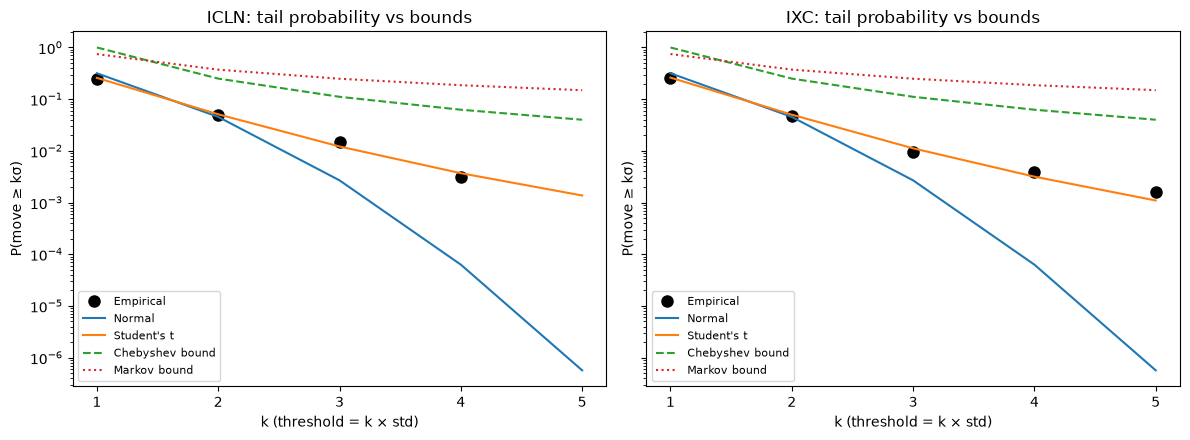

In [5]:
#stage 4 
print(tail_table.columns.tolist())
tail_table["Chebyshev bound"] = 1 / tail_table["k"] ** 2
tail_table["Cheb ÷ Empirical"] = tail_table["Chebyshev bound"] / tail_table["Empirical"]
tail_table["Cheb holds?"] = tail_table["Chebyshev bound"] >= tail_table["Empirical"]
print(tail_table["Cheb holds?"].all())
print(tail_table[["Ticker", "k", "Empirical", "Chebyshev bound", "Cheb ÷ Empirical", "Cheb holds?"]].round(4))
tail_table.to_csv("../outputs/tables/tab_tail_probabilities.csv", index=False, float_format="%.4g")

x = log_return["ICLN"]
s = x.std()
a = 3 * s                                # same threshold as Chebyshev at k = 3

e_abs = x.abs().mean()                   # E|r|, the average size of a move
markov = min(1, e_abs / a)               # the bound
emp_abs = (x.abs() >= a).mean()          # what actually happened

print(e_abs, a, markov, emp_abs)

for ticker in ["ICLN", "IXC"]:
    x = log_return[ticker]
    mu, s = x.mean(), x.std()
    e_abs = x.abs().mean()                   # ← new (outer loop)
    # ... your n_loc, nu, t_loc, t_scale lines ...

    for k in [1, 2, 3, 4, 5]:
        threshold = k * s
        # ... your emp, p_normal, p_t lines ...
        markov  = min(1, e_abs / threshold)          # ← new
        emp_abs = (x.abs() >= threshold).mean()      # ← new
        rows.append({"Ticker": ticker, "k": k, "Empirical": emp,
                     "Normal": p_normal, "Student's t": p_t,
                     "Markov bound": markov,         # ← new key
                     "Empirical |r|": emp_abs})      # ← new key

print(tail_table["Markov holds?"].all())       # should be True

sub = tail_table[tail_table["Ticker"] == "ICLN"]
print(sub[["k", "Empirical", "Chebyshev bound"]])
ax.semilogy(sub["k"], sub["Empirical"], "o", color="black", markersize=8, label="Empirical")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)   # create the figure IN this cell

for ax, ticker in zip(axes, ["ICLN", "IXC"]):
    sub = tail_table[tail_table["Ticker"] == ticker]

    ax.semilogy(sub["k"], sub["Empirical"], "o", color="black", markersize=8, label="Empirical")
    ax.semilogy(sub["k"], sub["Normal"], "-", label="Normal")
    ax.semilogy(sub["k"], sub['Student\'s t'], "-", label="Student's t")
    ax.semilogy(sub["k"], sub['Chebyshev bound'], "--", label="Chebyshev bound")
    ax.semilogy(sub["k"], sub['Markov bound'], ":", label="Markov bound")

    ax.set_title(f"{ticker}: tail probability vs bounds")
    ax.set_xlabel("k (threshold = k × std)")
    ax.set_ylabel("P(move ≥ kσ)")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("../outputs/figures/fig_bounds_vs_tails.png", dpi=150, bbox_inches="tight")
plt.show()

Stage 4: Markov and Chebyshev (Method 2)

Q1: Do the bounds ever fail?

No. Both bounds hold in all 10 rows (Cheb holds? and Markov holds? are all True). As theory guarantees, they’re valid for any distribution.

Q2: How loose are they, and does it change with k?

They get relatively looser further into the tail. Chebyshev overstates by about 4× at k = 1, 7× at k = 3 and 20× at k = 4 for ICLN (IXC: 3.9×, 11.6×, 15.7×, 25× at k = 5). Markov is worse: 17× at k = 3 and 58× at k = 4 for ICLN; 187× at k = 5 for IXC.
Why: from k = 3 to k = 4, the Chebyshev bound only falls by 1.8× (1/9 → 1/16), but the real tail (and the t) falls by about 3.3×. The bounds have to cover the worst-case distribution, which has far heavier tails than real returns.

Q3: Markov vs Chebyshev: which is tighter, and why?

Markov is tighter only at k = 1 (0.745 vs 1.0). From k = 2 on, Chebyshev is tighter. The lines cross at about k ≈ 1.3.
Why: Markov uses only the 1st moment (E|r|) and shrinks like 1/k. Chebyshev uses the 2nd moment (σ²) and shrinks like 1/k². More information about the distribution gives a faster-shrinking, tighter bound. In fact Chebyshev is Markov applied to (r − μ)².
A detail to mention: Markov’s event is |r| ≥ a (distance from zero), while Chebyshev’s is |r − μ| ≥ kσ (distance from the mean). That’s why the counts differ slightly: ICLN at 3σ has 18 vs 19 days, IXC at 5σ has 1 vs 2. Because the mean isn’t exactly zero, the two bands are shifted slightly relative to each other.

Q4: For a risk manager

Know or trust a model → use the t. It’s accurate to within a few days.
Know almost nothing about the distribution → use Chebyshev. It’s guaranteed, but you pay with heavy overstatement. At 3σ, Chebyshev says up to 11% of days could move more than about ±5.4%; in reality it was 1.5%. Capital or margin set from the bound would sit idle most of the time.
Chebyshev is identical for both ETFs, because it depends only on k. That’s its strength (no assumptions needed) and its weakness (it ignores everything the data tells you).

Q5: Clean vs traditional

At 3σ, Chebyshev is looser for IXC (11.6×) than for ICLN (7.3×), because IXC had fewer 3σ days (12 vs 19).
Further out, IXC’s ratio grows more slowly (25× at 5σ, with 2 actual days) than ICLN’s (no days at 5σ). IXC’s risk is concentrated in rarer but larger shocks, consistent with its higher kurtosis and negative skew. ICLN is more volatile day to day (std 0.018 vs 0.015) but had fewer truly extreme days.